In [476]:
# Neural Network Classification with Pytorch

# Classification is a problem of predicting whether something is one thing or another

In [477]:
# Make clasification data and get it ready

import sklearn
from sklearn.datasets import make_circles

n_samples = 1000
X, y = make_circles(n_samples, noise=0.03, random_state=42)

print(len(X), len(y))
print(f"First 5 samples of X:\n {X[:5]}")
print(f"First 5 samples of y:\n {y[:5]}")

1000 1000
First 5 samples of X:
 [[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]
First 5 samples of y:
 [1 1 1 1 0]


In [478]:
# Make DataFrame of circle
import pandas as pd

circles = pd.DataFrame({
    "X1": X[:, 0], 
    "X2": X[:, 1],
    "label": y
})
print(circles.head(10))

         X1        X2  label
0  0.754246  0.231481      1
1 -0.756159  0.153259      1
2 -0.815392  0.173282      1
3 -0.393731  0.692883      1
4  0.442208 -0.896723      0
5 -0.479646  0.676435      1
6 -0.013648  0.803349      1
7  0.771513  0.147760      1
8 -0.169322 -0.793456      1
9 -0.121486  1.021509      0


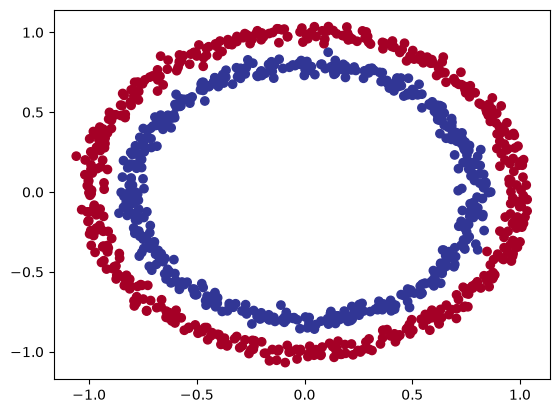

In [479]:
import matplotlib.pyplot as plt

plt.scatter(
    x = X[:, 0],
    y = X[:, 1],
    c = y,
    cmap = plt.cm.RdYlBu
)

# Note, the data we are working with is a toy data set
# Small enough to experiement, but sizeable enough to practice

In [480]:
# 1. Check input and output shapes

print(X.shape, y.shape)

X_sample = X[0]
y_sample = y[0]

print(f"Valeus for one sample of X: {X_sample} and the same for y: {y_sample}")
print(f"Shapes for one sample of X: {X_sample.shape} and the same for y: {y_sample.shape}")

(1000, 2) (1000,)
Valeus for one sample of X: [0.75424625 0.23148074] and the same for y: 1
Shapes for one sample of X: (2,) and the same for y: ()


In [481]:
# Turn data into tensors and create train and test splits

import torch

print(type(X), X.dtype)

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

print(X[:5], y[:5])
print(type(X), X.dtype, y.dtype)

<class 'numpy.ndarray'> float64
tensor([[ 0.7542,  0.2315],
        [-0.7562,  0.1533],
        [-0.8154,  0.1733],
        [-0.3937,  0.6929],
        [ 0.4422, -0.8967]]) tensor([1., 1., 1., 1., 0.])
<class 'torch.Tensor'> torch.float32 torch.float32


In [482]:
# Split data into train and test sets

from sklearn.model_selection import train_test_split

torch.manual_seed(42)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% of data is test, 80% of data is train
    random_state=42
) 

print(len(X_train), len(X_test), len(y_train), len(y_test))

800 200 800 200


In [483]:
# 2. Building a model

# Let's build a model to classify our red and blue dots

# To do so, we want to:
#   1. Setup device agnostic code
#   2. Construct a model (by subclassing nn.Module)
#   3. Define a loss function and optimizer
#   4. Create a training and test loop

from torch import nn

device = "cuda" if torch.cuda.is_available() else "cpu"

class CircleModelV0(nn.Module):
    def __init__(self):
        super().__init__()
        # self.layer_1 = nn.Linear(in_features=2, out_features=5) # Takes in 2 featuers and upscales to 5 features
        # self.layer_2 = nn.Linear(in_features=5, out_features=1) # in_features here must match previous out_features

        # Same thing
        self.two_linear_layers = nn.Sequential(
            nn.Linear(in_features=2, out_features=5),
            nn.Linear(in_features=5, out_features=1)
        )

    def forward(self, x):
        # return self.layer_2(self.layer_1) # x-> layer_1 -> layer_2
        return self.two_linear_layers(x)

model_0 = CircleModelV0().to(device)

print(model_0)
print(next(model_0.parameters()))
print(model_0.state_dict())

CircleModelV0(
  (two_linear_layers): Sequential(
    (0): Linear(in_features=2, out_features=5, bias=True)
    (1): Linear(in_features=5, out_features=1, bias=True)
  )
)
Parameter containing:
tensor([[ 0.5406,  0.5869],
        [-0.1657,  0.6496],
        [-0.1549,  0.1427],
        [-0.3443,  0.4153],
        [ 0.6233, -0.5188]], device='cuda:0', requires_grad=True)
OrderedDict({'two_linear_layers.0.weight': tensor([[ 0.5406,  0.5869],
        [-0.1657,  0.6496],
        [-0.1549,  0.1427],
        [-0.3443,  0.4153],
        [ 0.6233, -0.5188]], device='cuda:0'), 'two_linear_layers.0.bias': tensor([0.6146, 0.1323, 0.5224, 0.0958, 0.3410], device='cuda:0'), 'two_linear_layers.1.weight': tensor([[-0.0631,  0.3448,  0.0661, -0.2088,  0.1140]], device='cuda:0'), 'two_linear_layers.1.bias': tensor([-0.2060], device='cuda:0')})


In [484]:
with torch.inference_mode():
    untrained_preds = model_0(X_test.to(device))

print(f"Length of predictions: {len(untrained_preds)}, Shape: {untrained_preds.shape}")
print(f"Length of test sampels: {len(X_test)}, Shape: {X_test.shape}")
print(f"\nFirst 10 predictions:\n{torch.round(untrained_preds[:10])}")
print(f"\nFirst 10 labels:\n{y_test[:10]}")
print(X_test[:10], y_test[:10])

Length of predictions: 200, Shape: torch.Size([200, 1])
Length of test sampels: 200, Shape: torch.Size([200, 2])

First 10 predictions:
tensor([[-0.],
        [-0.],
        [-0.],
        [-0.],
        [-0.],
        [-0.],
        [-0.],
        [-0.],
        [-0.],
        [-0.]], device='cuda:0')

First 10 labels:
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])
tensor([[-0.3752,  0.6827],
        [ 0.0154,  0.9600],
        [-0.7028, -0.3147],
        [-0.2853,  0.9664],
        [ 0.4024, -0.7438],
        [ 0.6323, -0.5711],
        [ 0.8561,  0.5499],
        [ 1.0034,  0.1903],
        [-0.7489, -0.2951],
        [ 0.0538,  0.9739]]) tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [485]:
# Setup loss function and optimizer

# For regression, you might want MAE or MSE
# For classification you might want binary cross entropy or categorical cross entropy

# For optimizers, two of the most common are SGD and Adam among many others

# For loss function, we will use `torch.nn.BECWithLogitsLoss()`

loss_fn = nn.BCEWithLogitsLoss() # sigmoid activation function built-in
optimizer = torch.optim.SGD(
    params=model_0.parameters(),
    lr=0.1
)

In [486]:
# Calculate accuracy

# out of 100 examples, what percentage does our model get right?

def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = correct / len(y_pred) * 100
    return acc

In [487]:
# Train model

# going from raw logits -> prediction probabilities -> prediction labels

# Our model outputs are going to be raw logits, which will be converted to prediction probabilites
# by passing them to some kind of activation function, then we convert our model's prediction
# probabilities to prediction labels

model_0.eval()
with torch.inference_mode():
    y_logits = model_0(X_test.to(device))[:5]

print(y_logits)
print(y_test[:5])

# Use the sigmoid activation function on our model logits to turn them into prediction probabilities
y_pred_probs = torch.sigmoid(y_logits)
print(y_pred_probs)

# For our prediction probability values, we need to perform a range-style rounding on them
#   y_pred_probs >= 0.5, y = 1 (class 1)
#   y_pred_probs < 0.5, y = 0 (class 0)

y_preds = torch.round(y_pred_probs)

y_pred_labels = torch.round(torch.sigmoid(model_0(X_test.to(device))[:5]))
print(torch.eq(y_preds.squeeze(), y_pred_labels.squeeze()))

tensor([[-0.1269],
        [-0.0967],
        [-0.1908],
        [-0.1089],
        [-0.1667]], device='cuda:0')
tensor([1., 0., 1., 0., 1.])
tensor([[0.4683],
        [0.4758],
        [0.4524],
        [0.4728],
        [0.4584]], device='cuda:0')
tensor([True, True, True, True, True], device='cuda:0')


In [488]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 100

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    model_0.train()

    # 1. Forward pass
    y_logits = model_0(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    # loss = loss_fn(torch.sigmoid(y_logits), y_train) # nn.BCELoss() expects predictions probabilities as inputs 
    loss = loss_fn(
        y_logits, # nn.BCEWithLogitsLoss() expects raw logits as inputs
        y_train
    )
    acc = accuracy_fn(
        y_true = y_train,
        y_pred = y_pred
    )

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward (backpropagation)
    loss.backward()

    # 5. Optimizer step (gradient descent)
    optimizer.step()

    model_0.eval()
    with torch.inference_mode():
        test_logits = model_0(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f} | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")


Epoch: 0 | Loss: 0.69569, Acc: 50.00 | Test Loss: 0.69721, Test Acc: 50.00%


Epoch: 10 | Loss: 0.69403, Acc: 50.00 | Test Loss: 0.69615, Test Acc: 50.00%
Epoch: 20 | Loss: 0.69343, Acc: 46.00 | Test Loss: 0.69585, Test Acc: 48.50%
Epoch: 30 | Loss: 0.69321, Acc: 49.00 | Test Loss: 0.69577, Test Acc: 47.50%
Epoch: 40 | Loss: 0.69312, Acc: 49.50 | Test Loss: 0.69573, Test Acc: 46.50%
Epoch: 50 | Loss: 0.69308, Acc: 50.38 | Test Loss: 0.69569, Test Acc: 46.50%
Epoch: 60 | Loss: 0.69306, Acc: 50.50 | Test Loss: 0.69564, Test Acc: 46.50%
Epoch: 70 | Loss: 0.69305, Acc: 50.50 | Test Loss: 0.69559, Test Acc: 46.50%
Epoch: 80 | Loss: 0.69304, Acc: 50.75 | Test Loss: 0.69553, Test Acc: 46.50%
Epoch: 90 | Loss: 0.69303, Acc: 50.38 | Test Loss: 0.69547, Test Acc: 46.50%


In [489]:
# 4. Make predictions

# From the metrics, it looks like our model isn't learning anything
# So to inspect it, let's make it visual

import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

from helper_functions import plot_predictions, plot_decision_boundary

helper_functions.py already exists, skipping download


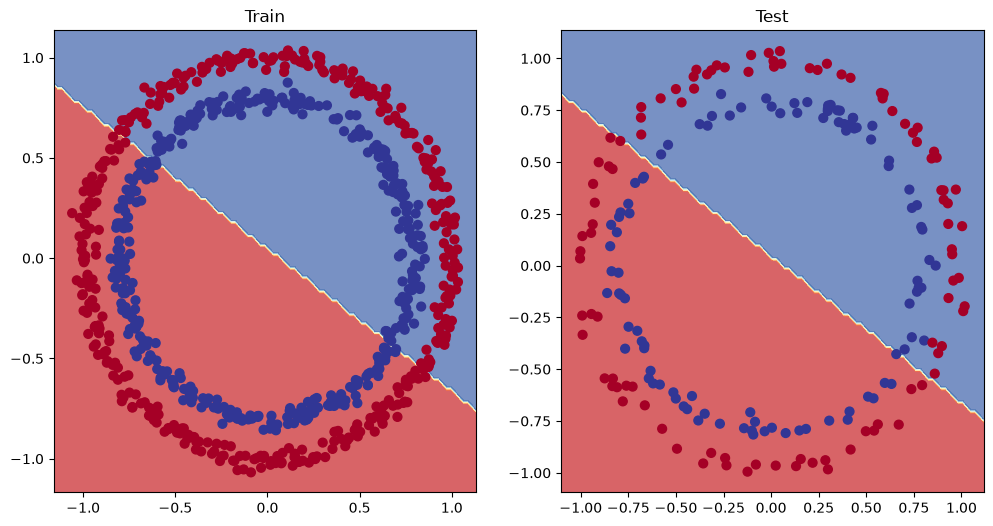

In [490]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_0, X_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_0, X_test, y_test)

# We cannot separate the data with one straight line!

In [491]:
# Improving a model from a model perspective

# 1. Add more layers - Give the model more chances to learn about patterns in the data
# 2. Add more hidden units - go from 5 hidden units to 10 hidden units to represent more complex patterns
# 3. Fit for longer
# 4. Changing the activation function
# 5. Change the learning rate - 
#   5a. exploding gradient
#   5b. vanishing gradient
# 6. Change the loss function

# All of these options are model's perpective because they deal with the model rather than the data
# They are all hyperparameters, that we can change ourselves

# Typically, we only change 1 value at a time to determine what makes a difference, here we won't

class CircleModelV1(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)

    def forward(self, x):
        # z = self.layer_1(x)
        # z = self.layer_2(z)
        # z = self.layer_3(z)
        # return z
        return self.layer_3(self.layer_2(self.layer_1(x)))

model_1 = CircleModelV1().to(device)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)

torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs = 1000

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

for epoch in range(epochs):
    model_1.train()

    y_logits = model_1(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_1.eval()
    with torch.inference_mode():
        test_logits = model_1(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f}, Acc: {acc:.2f} | Test Loss: {test_loss:.5f}, Test Acc: {test_acc:.2f}%")

Epoch: 0 | Loss: 0.69396, Acc: 50.88 | Test Loss: 0.69261, Test Acc: 51.00%
Epoch: 100 | Loss: 0.69305, Acc: 50.38 | Test Loss: 0.69379, Test Acc: 48.00%
Epoch: 200 | Loss: 0.69299, Acc: 51.12 | Test Loss: 0.69437, Test Acc: 46.00%
Epoch: 300 | Loss: 0.69298, Acc: 51.62 | Test Loss: 0.69458, Test Acc: 45.00%
Epoch: 400 | Loss: 0.69298, Acc: 51.12 | Test Loss: 0.69465, Test Acc: 46.00%
Epoch: 500 | Loss: 0.69298, Acc: 51.00 | Test Loss: 0.69467, Test Acc: 46.00%
Epoch: 600 | Loss: 0.69298, Acc: 51.00 | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 700 | Loss: 0.69298, Acc: 51.00 | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 800 | Loss: 0.69298, Acc: 51.00 | Test Loss: 0.69468, Test Acc: 46.00%
Epoch: 900 | Loss: 0.69298, Acc: 51.00 | Test Loss: 0.69468, Test Acc: 46.00%


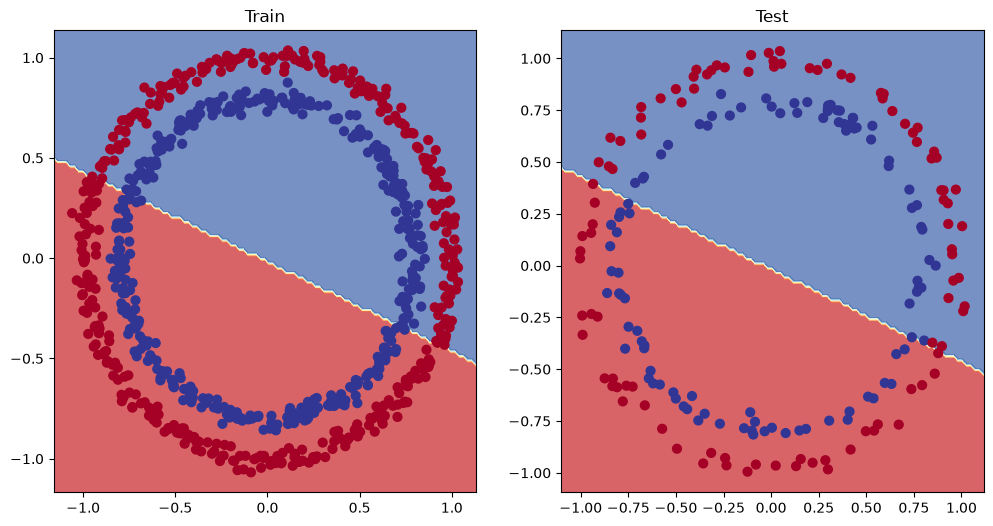

In [492]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_1, X_test, y_test)

100
tensor([[0.0000],
        [0.0100],
        [0.0200],
        [0.0300],
        [0.0400]]) tensor([[0.3000],
        [0.3070],
        [0.3140],
        [0.3210],
        [0.3280]])
80 20 80 20


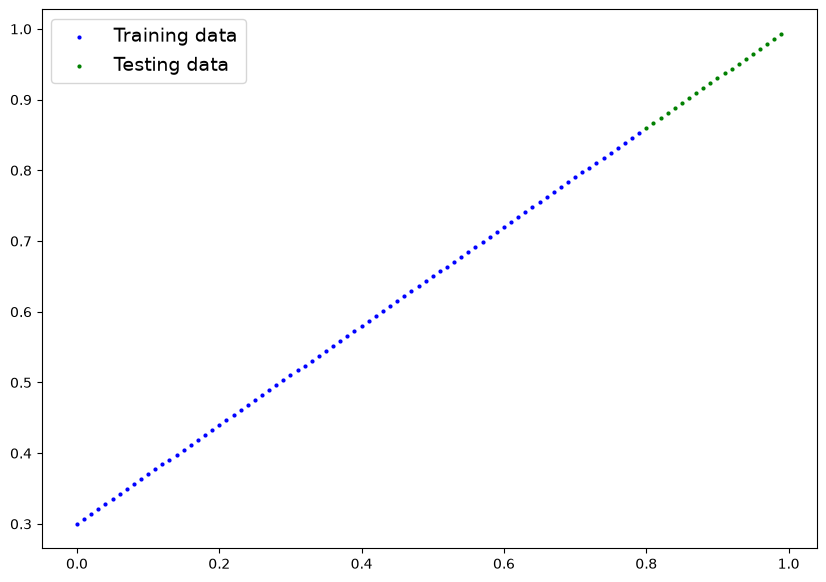

In [493]:
# Preparing data to see if our model can fit a straight line

# One way to troubleshoot a larger problem is to test out a smaller problem

weight = 0.7
bias = 0.3
start = 0
end = 1
step = 0.01

X_regression = torch.arange(start, end, step).unsqueeze(dim=1)
y_regression = weight * X_regression + bias

print(len(X_regression))
print(X_regression[:5], y_regression[:5])

train_split = int(0.8 * len(X_regression))
X_train_regression, y_train_regression = X_regression[:train_split], y_regression[:train_split]
X_test_regression, y_test_regression = X_regression[train_split:], y_regression[train_split:]

print(len(X_train_regression), len(X_test_regression), len(y_train_regression), len(y_test_regression))

plot_predictions(train_data=X_train_regression, train_labels=y_train_regression, test_data=X_test_regression, test_labels=y_test_regression)


In [494]:
model_2 = nn.Sequential(
    nn.Linear(in_features=1, out_features=10),
    nn.Linear(in_features=10, out_features=10),
    nn.Linear(in_features=10, out_features=1)
).to(device)

loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_2.parameters(), lr=0.01)

torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 1000

X_train_regression, y_train_regression = X_train_regression.to(device), y_train_regression.to(device)
X_test_regression, y_test_regression = X_test_regression.to(device), y_test_regression.to(device)

for epoch in range(epochs):
    y_pred = model_2(X_train_regression)
    loss = loss_fn(y_pred, y_train_regression)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_2.eval()
    with torch.inference_mode():
        test_pred = model_2(X_test_regression)
        test_loss = loss_fn(test_pred, y_test_regression)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.5f} | Test loss: {test_loss:.5f}")

# So model 2 can actually learn something. It can learn a linear regression,
# but not the current circle dataset. This could suggest that we need a non-
# linear model

Epoch: 0 | Loss: 0.75986 | Test loss: 0.91103
Epoch: 100 | Loss: 0.02858 | Test loss: 0.00081
Epoch: 200 | Loss: 0.02533 | Test loss: 0.00209
Epoch: 300 | Loss: 0.02137 | Test loss: 0.00305
Epoch: 400 | Loss: 0.01964 | Test loss: 0.00341
Epoch: 500 | Loss: 0.01940 | Test loss: 0.00387
Epoch: 600 | Loss: 0.01903 | Test loss: 0.00379
Epoch: 700 | Loss: 0.01878 | Test loss: 0.00381
Epoch: 800 | Loss: 0.01840 | Test loss: 0.00329
Epoch: 900 | Loss: 0.01798 | Test loss: 0.00360


In [495]:
# What patterns could you draw if you were given an infinite number of linear and non-linear
# lines? Almost anything

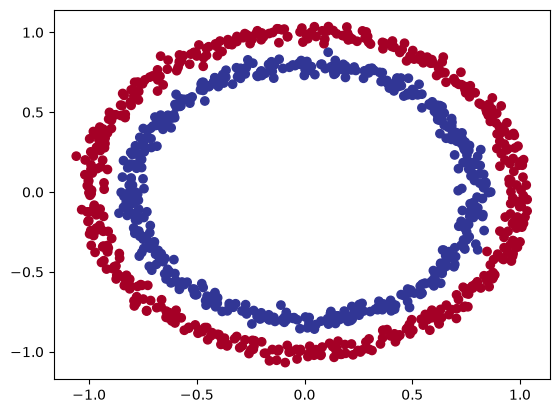

In [496]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

n_samples = 1000
X, y = make_circles(n_samples, noise=0.03, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu)

In [497]:
import torch
from sklearn.model_selection import train_test_split

X = torch.from_numpy(X).type(torch.float)
y = torch.from_numpy(y).type(torch.float)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train[:5], y_train[:5])

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        [-0.9666, -0.2256],
        [-0.1666,  0.7994]]) tensor([1., 0., 0., 0., 1.])


In [498]:
# Building a model with non-linearity

from torch import nn

class CircleModelV2(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer_1 = nn.Linear(in_features=2, out_features=10)
        self.layer_2 = nn.Linear(in_features=10, out_features=10)
        self.layer_3 = nn.Linear(in_features=10, out_features=1)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer_3(self.relu(self.layer_2(self.relu(self.layer_1(x)))))


model_3 = CircleModelV2().to(device)
print(model_3)

CircleModelV2(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)


In [499]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_3.parameters(), lr=0.1)

torch.manual_seed(42)
torch.cuda.manual_seed(42)

X_train, y_train = X_train.to(device), y_train.to(device)
X_test, y_test = X_test.to(device), y_test.to(device)

epochs = 1500
for epoch in range(epochs):
    model_3.train()
    
    y_logits = model_3(X_train).squeeze()
    y_pred = torch.round(torch.sigmoid(y_logits))

    loss = loss_fn(y_logits, y_train)
    acc = accuracy_fn(y_true=y_train, y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_3.eval()
    with torch.inference_mode():
        test_logits = model_3(X_test).squeeze()
        test_pred = torch.round(torch.sigmoid(test_logits))

        test_loss = loss_fn(test_logits, y_test)
        test_acc = accuracy_fn(y_true=y_test, y_pred=test_pred)

    if epoch % 100 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.4f} | Acc: {acc:.2f} | Test loss: {test_loss:.4f} | Test acc: {test_acc:.2f}%")

print(model_3.state_dict())



Epoch: 0 | Loss: 0.6929 | Acc: 50.00 | Test loss: 0.6932 | Test acc: 50.00%
Epoch: 100 | Loss: 0.6912 | Acc: 52.88 | Test loss: 0.6910 | Test acc: 52.50%
Epoch: 200 | Loss: 0.6898 | Acc: 53.37 | Test loss: 0.6894 | Test acc: 55.00%
Epoch: 300 | Loss: 0.6879 | Acc: 53.00 | Test loss: 0.6872 | Test acc: 56.00%
Epoch: 400 | Loss: 0.6852 | Acc: 52.75 | Test loss: 0.6841 | Test acc: 56.50%
Epoch: 500 | Loss: 0.6810 | Acc: 52.75 | Test loss: 0.6794 | Test acc: 56.50%
Epoch: 600 | Loss: 0.6751 | Acc: 54.50 | Test loss: 0.6729 | Test acc: 56.00%
Epoch: 700 | Loss: 0.6666 | Acc: 58.38 | Test loss: 0.6632 | Test acc: 59.00%
Epoch: 800 | Loss: 0.6516 | Acc: 64.00 | Test loss: 0.6476 | Test acc: 67.50%
Epoch: 900 | Loss: 0.6236 | Acc: 74.00 | Test loss: 0.6215 | Test acc: 79.00%
Epoch: 1000 | Loss: 0.5682 | Acc: 87.75 | Test loss: 0.5738 | Test acc: 86.50%
Epoch: 1100 | Loss: 0.4815 | Acc: 93.50 | Test loss: 0.4993 | Test acc: 90.50%
Epoch: 1200 | Loss: 0.3706 | Acc: 97.75 | Test loss: 0.4059 | Te

In [500]:
model_3.eval()
with torch.inference_mode():
    y_preds = torch.round(torch.sigmoid(model_3(X_test))).squeeze()
print(y_preds[:10], y_test[:10])

tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0') tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.], device='cuda:0')


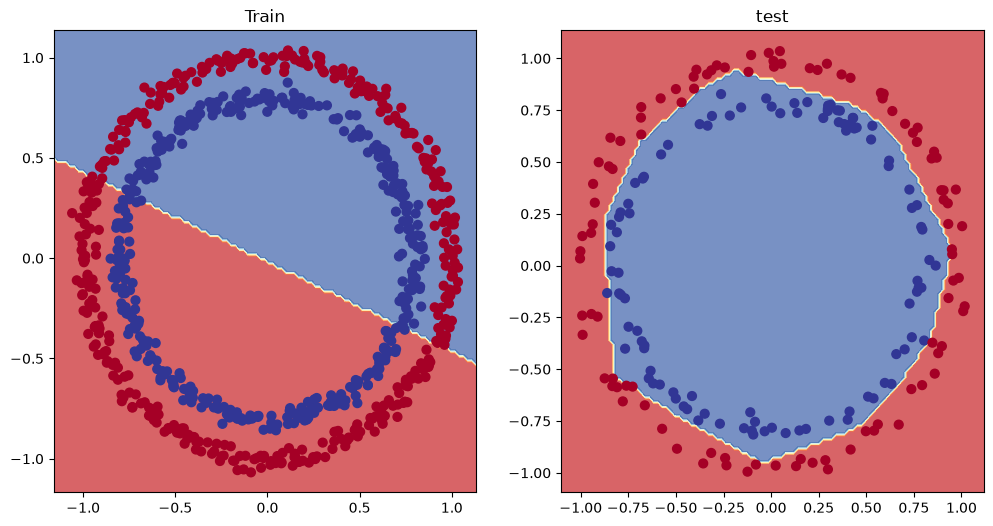

In [501]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_1, X_train, y_train)
plt.subplot(1, 2, 2)
plt.title("test")
plot_decision_boundary(model_3, X_test, y_test)

tensor([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,   1.,
          2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.])


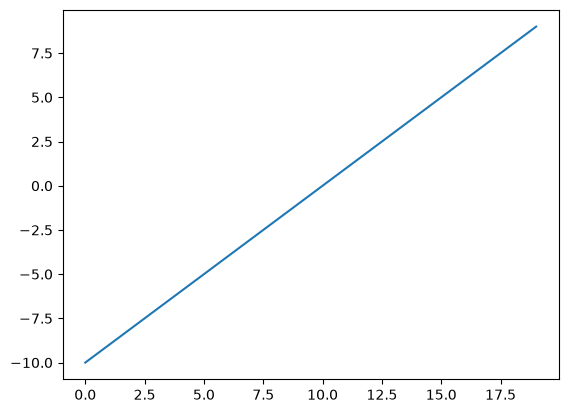

In [502]:
# Replicating non-linear activation functions

# Instead of us telling the model what to learn, we can give it the tools to discover patterns in data 
# and it tries to figure out the patterns on its own

A = torch.arange(-10, 10, 1, dtype=torch.float)
print(A)

plt.plot(A);

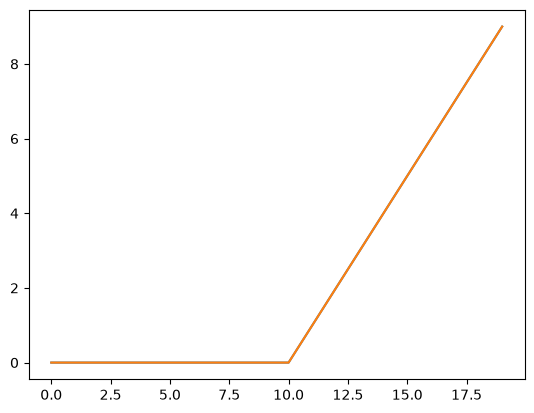

In [503]:

def relu(x: torch.Tensor) -> torch.Tensor:
    return torch.maximum(torch.tensor(0), x)

plt.plot(torch.relu(A))
plt.plot(relu(A))

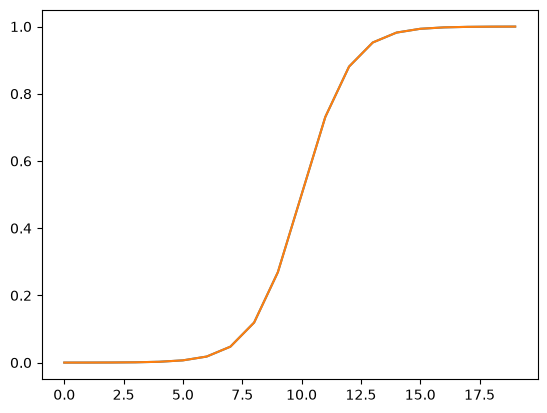

In [504]:
# Sigmoid

def sigmoid(x):
    return 1 / (1 + torch.exp(-x))

plt.plot(torch.sigmoid(A))
plt.plot(sigmoid(A))

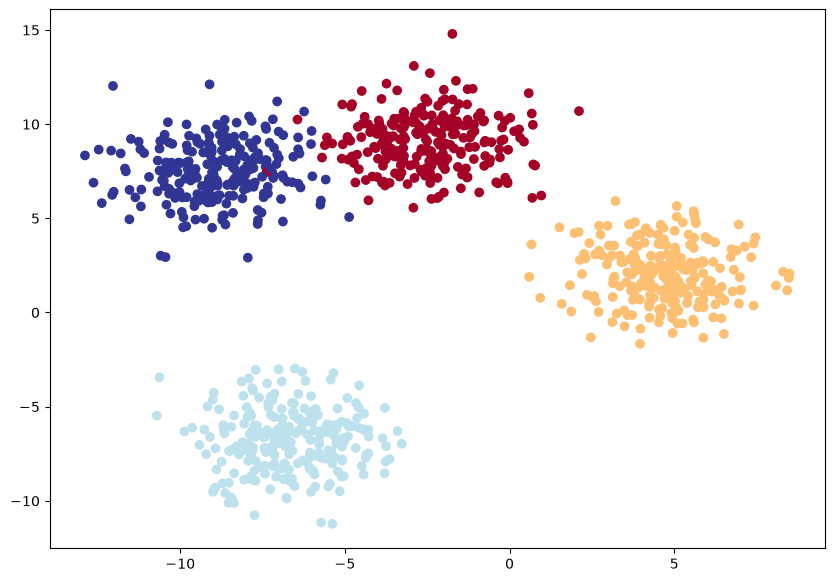

In [505]:
# Putting it all toegether with a multi-class classification

import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

# Set the hyperparameters
NUM_CLASSES = 4
NUM_FEATURES = 2
RANDOM_SEED = 42

# 1. Create multi-class data
X_blob, y_blob = make_blobs(
    n_samples=1000, 
    n_features=NUM_FEATURES, 
    centers=NUM_CLASSES,
    cluster_std=1.5, 
    random_state=RANDOM_SEED
)

# 2. Turn data into torch tensors
X_blob = torch.from_numpy(X_blob).type(torch.float)
y_blob = torch.from_numpy(y_blob).type(torch.LongTensor)

# 3. Split into train and test
X_blob_train, X_blob_test, y_blob_train, y_blob_test = train_test_split(
    X_blob,
    y_blob,
    test_size=0.2,
    random_state=RANDOM_SEED
)

# 4. Plot data
plt.figure(figsize=(10, 7))
plt.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap=plt.cm.RdYlBu)

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

class BlobModel(nn.Module):
    def __init__(self, input_features, output_features, hidden_units=8):
        super().__init__()

        self.linear_layer_stack = nn.Sequential(
            nn.Linear(in_features=input_features, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_features),
        )

    def forward(self, x):
        return self.linear_layer_stack(x)

model_4 = BlobModel(input_features=2, output_features=4, hidden_units=8).to(device)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_4.parameters(), lr=0.1)

In [508]:
model_4.eval()
with torch.inference_mode():
    y_logits = model_4(X_blob.to(device))

print(y_logits[:10])
print(y_blob_test[:10])

y_pred_probs = torch.softmax(y_logits, dim=1)
print(y_logits[:5])
print(y_pred_probs[:5])

y_preds = torch.argmax(y_pred_probs, dim=1)
print(y_preds)
print(y_blob_test)


tensor([[ 2.6800e-01, -3.6883e-01,  3.7261e-01,  2.1050e-01],
        [ 1.2173e+00, -2.0249e-01,  2.4939e-01,  2.0968e-01],
        [ 1.2674e+00, -2.2804e-01,  2.5983e-01,  2.2522e-01],
        [-1.7058e-02,  4.4641e-01,  3.2266e-01,  2.2436e-01],
        [-7.6205e-04,  4.2719e-01,  4.0871e-01,  2.6274e-01],
        [ 1.2721e+00, -2.6632e-01,  2.6205e-01,  2.2779e-01],
        [-7.9160e-02,  6.0116e-01,  3.3306e-01,  3.8544e-01],
        [ 1.1933e+00, -1.8250e-01,  2.3665e-01,  1.9892e-01],
        [ 1.0592e+00, -1.7606e-01,  1.9786e-01,  1.6332e-01],
        [-8.2052e-02,  5.3332e-01,  4.9025e-01,  4.4798e-01]], device='cuda:0')
tensor([1, 3, 2, 1, 0, 3, 2, 0, 2, 0])
tensor([[ 2.6800e-01, -3.6883e-01,  3.7261e-01,  2.1050e-01],
        [ 1.2173e+00, -2.0249e-01,  2.4939e-01,  2.0968e-01],
        [ 1.2674e+00, -2.2804e-01,  2.5983e-01,  2.2522e-01],
        [-1.7058e-02,  4.4641e-01,  3.2266e-01,  2.2436e-01],
        [-7.6205e-04,  4.2719e-01,  4.0871e-01,  2.6274e-01]], device='cuda

In [509]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epochs = 100
X_blob_train, y_blob_train = X_blob_train.to(device), y_blob_train.to(device)
X_blob_test, y_blob_test = X_blob_test.to(device), y_blob_test.to(device)

for epoch in range(epochs):
    model_4.train()

    y_logits = model_4(X_blob_train)
    y_pred = torch.softmax(y_logits, dim=1).argmax(dim=1)

    loss = loss_fn(y_logits, y_blob_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model_4.eval()
    with torch.inference_mode():
        test_logits = model_4(X_blob_test)
        test_preds = torch.softmax(test_logits, dim=1).argmax(dim=1)
        test_loss = loss_fn(test_logits, y_blob_test)
        test_acc = accuracy_fn(y_true=y_blob_test, y_pred=test_preds)

    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss:.4f}, Acc: {acc:.2f} | Test Loss: {test_loss:.4f}, Test acc: {test_acc:.2f}")

Epoch: 0 | Loss: 1.4101, Acc: 99.62 | Test Loss: 1.1330, Test acc: 47.50
Epoch: 10 | Loss: 0.2599, Acc: 99.62 | Test Loss: 0.2306, Test acc: 100.00
Epoch: 20 | Loss: 0.1032, Acc: 99.62 | Test Loss: 0.0937, Test acc: 99.50
Epoch: 30 | Loss: 0.0648, Acc: 99.62 | Test Loss: 0.0575, Test acc: 99.50
Epoch: 40 | Loss: 0.0498, Acc: 99.62 | Test Loss: 0.0427, Test acc: 99.50
Epoch: 50 | Loss: 0.0422, Acc: 99.62 | Test Loss: 0.0349, Test acc: 99.50
Epoch: 60 | Loss: 0.0377, Acc: 99.62 | Test Loss: 0.0301, Test acc: 99.50
Epoch: 70 | Loss: 0.0347, Acc: 99.62 | Test Loss: 0.0269, Test acc: 99.50
Epoch: 80 | Loss: 0.0326, Acc: 99.62 | Test Loss: 0.0246, Test acc: 99.50
Epoch: 90 | Loss: 0.0311, Acc: 99.62 | Test Loss: 0.0228, Test acc: 99.50


In [510]:
model_4.eval()

with torch.inference_mode():
    y_logits = model_4(X_blob_test)

print(y_logits[:10])

y_pred_probs =  torch.softmax(y_logits, dim=1)
print(y_pred_probs[:10])

y_preds = torch.argmax(y_pred_probs, dim=1)
print(y_preds[:10], y_blob_test)

tensor([[ 0.7492,  7.3999, -2.8711, -2.7182],
        [ 1.1975, -4.2905, -1.2525,  6.8084],
        [-1.7357, -1.4723,  6.7291, -1.4901],
        [-0.3871,  5.2955, -1.3658, -1.5771],
        [ 6.5572,  0.6781, -4.0950, -2.4466],
        [ 1.2285, -5.2008, -1.3587,  8.2662],
        [-1.6462, -1.1604,  6.2038, -1.3460],
        [ 5.9077, -1.5094, -3.1053, -0.7459],
        [-2.0801, -2.4914,  7.7556, -1.1936],
        [ 6.2180, -0.9652, -3.3967, -1.4634]], device='cuda:0')
tensor([[1.2913e-03, 9.9863e-01, 3.4575e-05, 4.0288e-05],
        [3.6435e-03, 1.5069e-05, 3.1439e-04, 9.9603e-01],
        [2.1060e-04, 2.7407e-04, 9.9925e-01, 2.6924e-04],
        [3.3853e-03, 9.9431e-01, 1.2721e-03, 1.0299e-03],
        [9.9706e-01, 2.7893e-03, 2.3580e-05, 1.2259e-04],
        [8.7731e-04, 1.4157e-06, 6.5998e-05, 9.9906e-01],
        [3.8914e-04, 6.3257e-04, 9.9845e-01, 5.2542e-04],
        [9.9799e-01, 5.9966e-04, 1.2157e-04, 1.2868e-03],
        [5.3496e-05, 3.5456e-05, 9.9978e-01, 1.2980e-04],


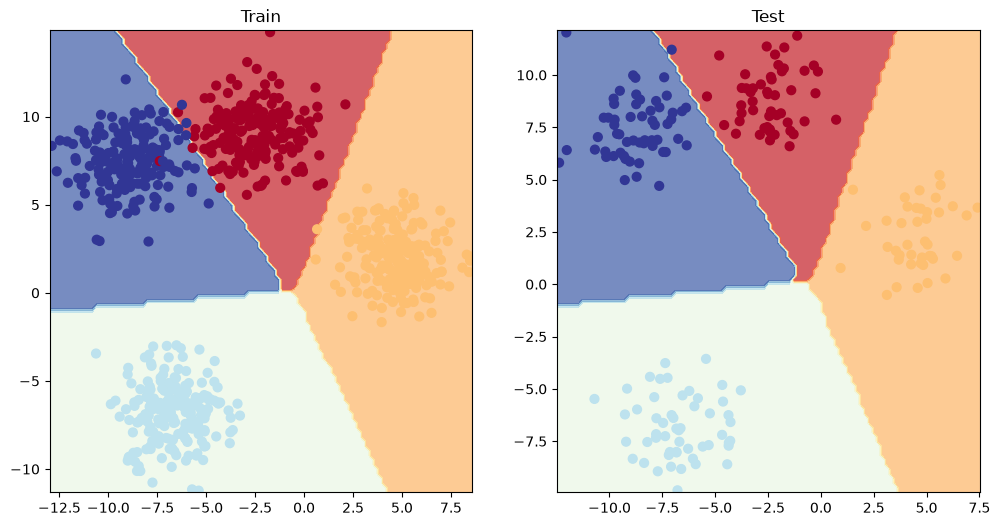

In [511]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(model_4, X_blob_train, y_blob_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(model_4, X_blob_test, y_blob_test)
